# Khảo sát ngưỡng thu nhập cao — chưa chọn ngưỡng lọc chính

**09/11/2026.** Mục đích: xem ngưỡng nào loại bao nhiêu hộ và ảnh hưởng thế nào đến bốn câu hỏi thu nhập. Không chọn ngưỡng để đạt p-value mong muốn; notebook này **chỉ khảo sát mô tả và phân phối**, chưa chạy lại kiểm định tăng/giảm.

Tiền dùng **triệu đồng/người/năm, giá 2010**. Giữ nguyên Excel, nhãn Q và [notebook toàn mẫu](thu_nhap_4_cau_2010_2014.ipynb).

**Đối chiếu lại 10/11/2026:** Cục Thống kê xác nhận CPI bình quân cùng gốc 2010 = 100 là **2010: 100,00; 2014: 143,69**. Đây khác mức tăng so với năm trước (2010: 9,19%; 2014: 4,09%). [Nguồn và phép kiểm tra](CPI_nguon_va_cach_quy_doi.md). Hệ số quy đổi và kết quả thu nhập giữ nguyên.

## 1. Quy tắc trong lớp và ý nghĩa của việc lọc

**Chap 2, trang PDF 24–26:** IQR = phân vị 75% − phân vị 25%.

- Cờ outlier phía trên: $Y>q_{0.75}+1.5\,IQR$.
- Cờ extreme phía trên: $Y>q_{0.75}+3\,IQR$.
- Trong công thức này, $q_{0.25},q_{0.75}$ là **các mức tiền tại phân vị**, khác với nhãn nhóm `Quart` = 1/2/3/4.
- Công thức phân vị trong slide dùng vị trí $(n+1)p$. Code dùng `np.quantile(..., method="weibull")` để khớp cách nội suy đó.

**Gắn cờ ≠ chứng minh dữ liệu sai ≠ bắt buộc xóa.** Thu nhập có thể lệch phải thật. Nếu bỏ các hộ thu nhập cao, mean/variance/gap sau lọc chỉ mô tả phần dân số được giữ, không còn cùng tham số toàn mẫu.

Hướng dẫn World Bank phân biệt phát hiện và xử lý outlier, khuyến nghị ghi rõ quy tắc và đối chiếu có/không lọc, áp dụng nhất quán giữa các năm. Nguồn tham khảo đúng phần này: [Mancini & Vecchi (2022), §7.3 và Box 10.6](https://documents1.worldbank.org/curated/en/099225003092220001/pdf/P1694340e80f9a00a09b20042de5a9cd47e.pdf).

In [1]:
from pathlib import Path
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import Markdown, display

project_directory = next(
    folder for folder in [Path.cwd(), *Path.cwd().parents]
    if (folder / "dataset/VHLSS_2014.xls").exists()
)
data_file = project_directory / "dataset/VHLSS_2014.xls"
output_directory = project_directory / "bao_cao_vhlss"
original_excel_hash = hashlib.sha256(data_file.read_bytes()).hexdigest()
cpi_table = pd.read_csv(output_directory / "cpi_2010_2014.csv")
cpi_by_year = cpi_table.set_index("nam")["cpi_binh_quan_2010_bang_100"]
years = [2010, 2014]
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda number: f"{number:,.3f}")

In [2]:
income_by_year = {}
audit_rows = []
for year in years:
    original_data = pd.read_excel(data_file, sheet_name=str(year))
    valid_rows = (
        np.isfinite(original_data["income"]) & original_data["income"].ge(0)
        & np.isfinite(original_data["size"]) & original_data["size"].gt(0)
        & original_data["Quart"].isin([1, 2, 3, 4])
    )
    household_data = original_data.loc[valid_rows,
        ["income", "size", "Quart", "province", "area"]].copy()
    household_data["excel_row"] = household_data.index + 2
    household_data["year"] = year
    household_data["real_income_per_person"] = (
        household_data["income"] / household_data["size"]
        / 1000 * 100 / cpi_by_year.loc[year]
    )
    income_by_year[year] = household_data
    stored_per_person_column = "Inc_head" if year == 2010 else "inc_head"
    stored_per_person_difference = np.abs(
        original_data.loc[valid_rows, stored_per_person_column]
        - original_data.loc[valid_rows, "income"] / original_data.loc[valid_rows, "size"]
    ).max()
    audit_rows.append({
        "year": year, "original_n": len(original_data), "valid_n": len(household_data),
        "max_Inc_head_difference_thousand_VND": stored_per_person_difference,
    })
display(pd.DataFrame(audit_rows))

,year,original_n,valid_n,max_Inc_head_difference_thousand_VND
0,2010,9399,9399,0.000
1,2014,9398,9398,0.000


## 2. Những hộ lớn nhất có dấu hiệu gì?

Bảng dưới giúp kiểm tra bản ghi. `income` vẫn là **nghìn đồng/hộ/năm**; `real_income_per_person` là **triệu đồng/người/năm, giá 2010**. Chênh lệch lớn với hộ kế tiếp là dấu hiệu cần xem lại nguồn, chưa chứng minh lỗi nhập liệu. `Inc_head` khớp phép chia chỉ xác nhận nhất quán nội bộ, không xác nhận thu nhập gốc đúng.

In [3]:
top_households = pd.concat([
    income_by_year[year].nlargest(5, "real_income_per_person")
    for year in years
])
display(top_households[[
    "year", "excel_row", "province", "area", "Quart", "income", "size", "real_income_per_person",
]])

influence_rows = []
for year in years:
    for scope in ["All", "Q4"]:
        group = income_by_year[year]
        if scope == "Q4":
            group = group.loc[group["Quart"].eq(4)]
        values = group["real_income_per_person"]
        squared_deviations = (values - values.mean()) ** 2
        influence_rows.append({
            "year": year, "scope": scope,
            "largest_income": values.max(),
            "largest_point_SS_percent": 100 * squared_deviations.max() / squared_deviations.sum(),
        })
display(pd.DataFrame(influence_rows))

,year,excel_row,province,area,Quart,income,size,real_income_per_person
6662,2010,6664,74,2,4,"8,655,550.000",3,"2,885.183"
6711,2010,6713,74,2,4,"2,140,093.000",4,535.023
6860,2010,6862,75,2,4,"1,065,400.000",2,532.700
3187,2010,3189,34,2,4,"900,141.000",2,450.070
7196,2010,7198,79,1,4,"1,985,334.000",5,397.067
7112,2014,7114,77,2,4,"4,014,000.000",4,698.378
8591,2014,8593,91,1,4,"1,633,400.000",2,568.376
8964,2014,8966,93,1,4,"2,646,980.000",5,368.429
397,2014,399,1,2,4,"482,600.000",1,335.862
86,2014,88,1,1,4,"989,000.000",3,229.429


,year,scope,largest_income,largest_point_SS_percent
0,2010,All,"2,885.183",67.987
1,2010,Q4,"2,885.183",78.007
2,2014,All,698.378,11.977
3,2014,Q4,698.378,21.872


## 3. Các phương án khảo sát

| Nhóm quy tắc | Cách làm | Ý nghĩa |
|---|---|---|
| Toàn mẫu | Giữ tất cả hộ hợp lệ | Mốc đối chiếu |
| Bỏ 1 hộ cao nhất/năm | Cùng quy tắc ở hai năm | Chẩn đoán ảnh hưởng tối thiểu, không gọi là sửa lỗi |
| Bỏ top 0,1%; 0,5%; 1%/năm | Bỏ $k=\lceil n\times r\rceil$ hộ cao nhất | Giới hạn tỷ lệ loại; ngưỡng tiền thay đổi theo năm |
| Cờ 1,5×IQR và 3×IQR | Giữ hộ dưới ngưỡng boxplot của từng năm | Quy tắc phát hiện trong Chap 2; chưa tự là quy tắc xóa |
| Trần chung 200 hoặc 500 triệu giá 2010 | Cùng ngưỡng tiền thực cả hai năm | So cùng giới hạn thu nhập; **hai trần chỉ là kịch bản minh họa, không phải chuẩn siêu giàu** |

Với top-r%, code dùng **số thứ tự**, không phụ thuộc cách nội suy phân vị; làm tròn lên nên top 0,1% ở đây là 10 hộ/năm. Cột tỷ lệ loại thực tế cho biết sai khác làm tròn. Nếu có thu nhập bằng nhau tại ranh giới, code dừng để tránh chọn tùy tiện; dữ liệu hiện tại không có vấn đề đó ở các ngưỡng rank này.

Các cách lọc cùng tỷ lệ mỗi năm và cùng mức tiền trả lời những câu hỏi khác nhau. Chỉ khảo sát phía trên, không lọc hộ thu nhập thấp.

In [4]:
rules = [
    {"rule": "Toàn mẫu", "kind": "all", "value": None},
    {"rule": "Bỏ 1 hộ/năm", "kind": "count", "value": 1},
    {"rule": "Bỏ top 0,1%", "kind": "fraction", "value": 0.001},
    {"rule": "Bỏ top 0,5%", "kind": "fraction", "value": 0.005},
    {"rule": "Bỏ top 1%", "kind": "fraction", "value": 0.01},
    {"rule": "Cờ 3×IQR", "kind": "iqr", "value": 3.0},
    {"rule": "Cờ 1,5×IQR", "kind": "iqr", "value": 1.5},
    {"rule": "Trần 500 triệu", "kind": "fixed", "value": 500.0},
    {"rule": "Trần 200 triệu", "kind": "fixed", "value": 200.0},
]

def retained_households(households, rule):
    values = households["real_income_per_person"]
    if rule["kind"] == "all":
        return households.copy(), np.nan
    if rule["kind"] in ["fraction", "count"]:
        remove_count = (
            int(np.ceil(len(households) * rule["value"]))
            if rule["kind"] == "fraction" else rule["value"]
        )
        sorted_households = households.sort_values("real_income_per_person", ascending=False)
        smallest_removed = sorted_households.iloc[remove_count - 1]["real_income_per_person"]
        largest_retained = sorted_households.iloc[remove_count]["real_income_per_person"]
        assert smallest_removed > largest_retained, "Có đồng hạng ở ngưỡng; cần quy tắc riêng."
        return sorted_households.iloc[remove_count:].copy(), largest_retained
    if rule["kind"] == "iqr":
        lower_quartile, upper_quartile = np.quantile(values, [.25, .75], method="weibull")
        cutoff = upper_quartile + rule["value"] * (upper_quartile - lower_quartile)
    else:
        cutoff = rule["value"]
    return households.loc[values.le(cutoff)].copy(), cutoff

# Ngưỡng và mask được dùng chung cho mọi chỉ tiêu trong cùng phương án/năm.
scenario_data = {}
scenario_rows = []
distribution_rows = []
for rule in rules:
    for year in years:
        original = income_by_year[year]
        kept, cutoff = retained_households(original, rule)
        scenario_data[(rule["rule"], year)] = kept
        values = kept["real_income_per_person"]
        group_means = kept.groupby("Quart")["real_income_per_person"].mean()
        removed = original.loc[~original.index.isin(kept.index)]
        row = {
            "rule": rule["rule"], "year": year, "cutoff_million_2010": cutoff,
            "original_n": len(original), "removed_n": len(removed), "kept_n": len(kept),
            "removed_percent": 100 * len(removed) / len(original),
            "removed_all_from_Q4": bool(removed["Quart"].eq(4).all()) if len(removed) else True,
            "mean": values.mean(), "median": values.median(), "variance": values.var(ddof=1),
            "Q1_mean": group_means.loc[1], "Q2_mean": group_means.loc[2],
            "Q3_mean": group_means.loc[3], "Q4_mean": group_means.loc[4],
            "Q4_kept_n": int(kept["Quart"].eq(4).sum()),
            "gap_Q4_minus_Q1": group_means.loc[4] - group_means.loc[1],
            "ratio_Q4_over_Q1": group_means.loc[4] / group_means.loc[1],
        }
        scenario_rows.append(row)
        for scope in ["All", "Q4"]:
            group_values = values if scope == "All" else kept.loc[kept["Quart"].eq(4), "real_income_per_person"]
            squared_deviations = (group_values - group_values.mean()) ** 2
            jb_statistic = stats.jarque_bera(group_values).statistic
            distribution_rows.append({
                "rule": rule["rule"], "year": year, "scope": scope, "n": len(group_values),
                "skewness": stats.skew(group_values), "JB": jb_statistic,
                "JB_log10_p": -jb_statistic / (2 * np.log(10)),
                "reject_normality_5pct": bool(jb_statistic > stats.chi2.ppf(.95, df=2)),
                "largest_point_SS_percent": 100 * squared_deviations.max() / squared_deviations.sum(),
            })

scenario_summary = pd.DataFrame(scenario_rows)
distribution_summary = pd.DataFrame(distribution_rows)
display(scenario_summary[[
    "rule", "year", "cutoff_million_2010", "removed_n", "kept_n", "removed_percent",
    "mean", "variance", "gap_Q4_minus_Q1", "ratio_Q4_over_Q1",
]])

,rule,year,cutoff_million_2010,removed_n,kept_n,removed_percent,mean,variance,gap_Q4_minus_Q1,ratio_Q4_over_Q1
0,Toàn mẫu,2010,NaN,0,9399,0.000,18.257,"1,286.388",35.036,7.665
1,Toàn mẫu,2014,NaN,0,9398,0.000,20.861,407.866,37.098,6.896
2,Bỏ 1 hộ/năm,2010,535.023,1,9398,0.011,17.952,411.763,33.825,7.435
3,Bỏ 1 hộ/năm,2014,568.376,1,9397,0.011,20.789,359.050,36.820,6.852
4,"Bỏ top 0,1%",2010,236.250,10,9389,0.106,17.598,271.865,32.487,7.180
5,"Bỏ top 0,1%",2014,175.726,10,9388,0.106,20.543,282.347,35.918,6.709
6,"Bỏ top 0,5%",2010,113.037,47,9352,0.500,17.061,194.620,30.629,6.827
7,"Bỏ top 0,5%",2014,118.043,47,9351,0.500,20.080,228.215,34.386,6.465
8,Bỏ top 1%,2010,83.297,94,9305,1.000,16.640,159.933,29.285,6.571
9,Bỏ top 1%,2014,89.502,94,9304,1.000,19.670,195.722,33.127,6.265


## 4. So sánh thay đổi 2014 − 2010

Đây là **so sánh mô tả**, chưa có p-value hay kết luận về tổng thể. Với mỗi phương án, giữ nhãn Q gốc: Q4 sau lọc là **phần còn lại của Q4 ban đầu**, không phải nhóm giàu nhất mới chiếm đúng 25%.

In [5]:
comparison_rows = []
for rule in rules:
    rows = scenario_summary.loc[scenario_summary["rule"].eq(rule["rule"])].set_index("year")
    earlier, later = rows.loc[2010], rows.loc[2014]
    comparison_rows.append({
        "rule": rule["rule"],
        "removed_2010": int(earlier["removed_n"]), "removed_2014": int(later["removed_n"]),
        "mean_2010": earlier["mean"], "mean_2014": later["mean"],
        "mean_change_percent": 100 * (later["mean"] / earlier["mean"] - 1),
        "variance_2010": earlier["variance"], "variance_2014": later["variance"],
        "variance_change_percent": 100 * (later["variance"] / earlier["variance"] - 1),
        "gap_2010": earlier["gap_Q4_minus_Q1"], "gap_2014": later["gap_Q4_minus_Q1"],
        "gap_change": later["gap_Q4_minus_Q1"] - earlier["gap_Q4_minus_Q1"],
    })
comparison = pd.DataFrame(comparison_rows)
display(comparison)

,rule,removed_2010,removed_2014,mean_2010,mean_2014,mean_change_percent,variance_2010,variance_2014,variance_change_percent,gap_2010,gap_2014,gap_change
0,Toàn mẫu,0,0,18.257,20.861,14.261,"1,286.388",407.866,-68.294,35.036,37.098,2.062
1,Bỏ 1 hộ/năm,1,1,17.952,20.789,15.801,411.763,359.050,-12.802,33.825,36.820,2.994
2,"Bỏ top 0,1%",10,10,17.598,20.543,16.731,271.865,282.347,3.855,32.487,35.918,3.431
3,"Bỏ top 0,5%",47,47,17.061,20.080,17.692,194.620,228.215,17.262,30.629,34.386,3.756
4,Bỏ top 1%,94,94,16.640,19.670,18.210,159.933,195.722,22.378,29.285,33.127,3.841
5,Cờ 3×IQR,180,161,16.115,19.225,19.298,131.347,169.514,29.058,27.766,31.853,4.087
6,"Cờ 1,5×IQR",519,474,14.774,17.824,20.646,86.099,116.020,34.751,24.391,28.343,3.952
7,Trần 500 triệu,3,2,17.842,20.730,16.187,355.177,327.169,-7.886,33.404,36.596,3.192
8,Trần 200 triệu,17,8,17.450,20.578,17.926,242.543,288.284,18.859,31.951,36.043,4.091


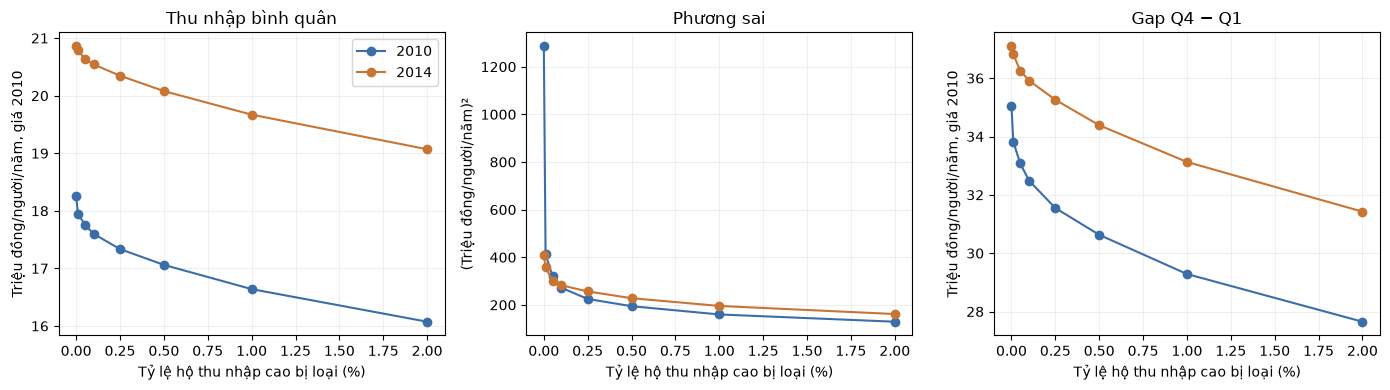

In [6]:
# Đường nhạy theo mức cắt: cùng tỷ lệ rank ở hai năm, không chạy test theo từng ngưỡng.
cut_fractions = [0, .0001, .0005, .001, .0025, .005, .01, .02]
curve_rows = []
for fraction in cut_fractions:
    for year in years:
        rule = {"kind": "all", "value": None} if fraction == 0 else {"kind": "fraction", "value": fraction}
        kept, _ = retained_households(income_by_year[year], rule)
        group_means = kept.groupby("Quart")["real_income_per_person"].mean()
        curve_rows.append({
            "year": year, "cut_percent": 100 * fraction,
            "mean": kept["real_income_per_person"].mean(),
            "variance": kept["real_income_per_person"].var(ddof=1),
            "gap": group_means.loc[4] - group_means.loc[1],
        })
curve = pd.DataFrame(curve_rows)
figure, axes = plt.subplots(1, 3, figsize=(14, 4))
for year, color in [(2010, "#3B6EA8"), (2014, "#C87533")]:
    year_curve = curve.loc[curve["year"].eq(year)]
    for axis, variable, title in zip(axes, ["mean", "variance", "gap"],
                                   ["Thu nhập bình quân", "Phương sai", "Gap Q4 − Q1"]):
        axis.plot(year_curve["cut_percent"], year_curve[variable], marker="o", color=color, label=str(year))
        axis.set_title(title)
        axis.set_xlabel("Tỷ lệ hộ thu nhập cao bị loại (%)")
        axis.grid(alpha=.2)
axes[0].set_ylabel("Triệu đồng/người/năm, giá 2010")
axes[1].set_ylabel("(Triệu đồng/người/năm)²")
axes[2].set_ylabel("Triệu đồng/người/năm, giá 2010")
axes[0].legend()
figure.tight_layout()
plt.show()

## 5. Lọc rồi có dùng F-test được chưa?

Kiểm tra JB **đúng mẫu sau lọc** theo Chap 9 trang 21. Bác bỏ chuẩn không tự cấm mọi xấp xỉ cho mean, nhưng F-test **phương sai** của Chap 7 §7.3 vẫn cần giả định chuẩn. Không được coi việc bớt outlier là đã đáp ứng giả định ấy.

In [7]:
display(distribution_summary[[
    "rule", "year", "scope", "n", "skewness", "JB", "JB_log10_p",
    "largest_point_SS_percent", "reject_normality_5pct",
]])
print("Số mẫu còn bác bỏ chuẩn:", int(distribution_summary["reject_normality_5pct"].sum()),
      "/", len(distribution_summary))

,rule,year,scope,n,skewness,JB,JB_log10_p,largest_point_SS_percent,reject_normality_5pct
0,Toàn mẫu,2010,All,9399,56.001,"7,444,431,498.782","-1,616,537,760.414",67.987,True
1,Toàn mẫu,2010,Q4,2350,34.200,"201,130,654.380","-43,674,966.669",78.007,True
2,Toàn mẫu,2014,All,9398,9.126,"18,553,111.075","-4,028,756.881",11.977,True
3,Toàn mẫu,2014,Q4,2349,9.809,"2,939,217.874","-638,243.052",21.872,True
4,Bỏ 1 hộ/năm,2010,All,9398,9.179,"10,686,687.341","-2,320,584.671",6.910,True
5,Bỏ 1 hộ/năm,2010,Q4,2349,7.896,"872,393.644","-189,437.873",10.795,True
6,Bỏ 1 hộ/năm,2014,All,9397,6.197,"4,535,814.244","-984,939.549",8.888,True
7,Bỏ 1 hộ/năm,2014,Q4,2348,7.058,"1,001,307.290","-217,431.115",18.007,True
8,"Bỏ top 0,1%",2010,All,9389,4.045,"371,289.804","-80,624.557",1.873,True
9,"Bỏ top 0,1%",2010,Q4,2340,3.827,"48,672.486","-10,569.096",3.600,True


Số mẫu còn bác bỏ chuẩn: 36 / 36


## 6. Đề xuất từ khảo sát

1. **Giữ toàn mẫu làm mốc chính** vì chưa có bằng chứng hộ thu nhập cao là lỗi. Phương sai rất nhạy với đuôi, nên việc cắt đuôi làm đổi hẳn đối tượng của câu hỏi 3.
2. Nếu muốn trình bày thêm phần hộ ngoài nhóm thu nhập cực cao, **bản bỏ top 0,1% mỗi năm** là kịch bản nhẹ để đối chiếu: chỉ 10 hộ/năm và ảnh hưởng của một điểm giảm mạnh. Đây là lựa chọn khảo sát ít loại hộ, **không phải ngưỡng siêu giàu chuẩn hay ngưỡng tối ưu được chứng minh**. Top 0,5% và 1% dùng để cho thấy kết quả nhạy thế nào với mức cắt.
3. **3×IQR là quy tắc gắn cờ rõ trong lớp**, nhưng tự động bỏ toàn bộ các cờ này loại khoảng 1,7–1,9% mẫu; không đương nhiên hợp lý hơn vì thu nhập vốn lệch phải. Không khuyên dùng 1,5×IQR để xóa hàng loạt hộ ở đây.
4. Không chọn ngưỡng vì làm variance/gap giảm hoặc vì test có ý nghĩa. Chưa có quy tắc nào ở khảo sát này xác minh hộ nào sai; chưa đổi bản kiểm định chính.

Nếu sau đó kiểm định trên dữ liệu cắt theo phân vị mẫu, không nên giữ nguyên công thức SE như thể ngưỡng đã biết: ngưỡng được ước lượng cũng có bất định. Trần tiền thực được cố định từ trước có ý nghĩa khác với cắt theo thứ hạng. Notebook này chưa đưa ra p-value mới sau lọc.

In [8]:
baseline = comparison.set_index("rule").loc["Toàn mẫu"]
light_trim = comparison.set_index("rule").loc["Bỏ top 0,1%"]
display(Markdown(
    f"**Điểm rút ra:** thu nhập bình quân trong mẫu tăng ở cả {len(comparison)} phương án. "
    "Gap tuyệt đối Q4−Q1 trong mẫu cũng tăng ở tất cả các phương án đã khảo sát. "
    f"Riêng variance: toàn mẫu giảm **{-baseline['variance_change_percent']:.2f}%**, "
    f"nhưng bỏ top 0,1% mỗi năm thì **tăng {light_trim['variance_change_percent']:.2f}%**. "
    "Vì vậy không thể coi nhận định variance giảm là vững trước lựa chọn cách xử lý đuôi. "
    "Các số này là mô tả, chưa phải kết luận kiểm định tăng/giảm sau cắt mẫu."
))

**Điểm rút ra:** thu nhập bình quân trong mẫu tăng ở cả 9 phương án. Gap tuyệt đối Q4−Q1 trong mẫu cũng tăng ở tất cả các phương án đã khảo sát. Riêng variance: toàn mẫu giảm **68.29%**, nhưng bỏ top 0,1% mỗi năm thì **tăng 3.86%**. Vì vậy không thể coi nhận định variance giảm là vững trước lựa chọn cách xử lý đuôi. Các số này là mô tả, chưa phải kết luận kiểm định tăng/giảm sau cắt mẫu.

**Ghi chú để chốt hướng:**

_Có giữ toàn mẫu làm chính và thêm bản top 0,1% để đối chiếu không? Nếu đổi đối tượng sang “ngoài nhóm thu nhập cao nhất”, cần ghi rõ trong cả bốn câu hỏi._

In [9]:
# Đối chiếu cùng bộ lọc cho mean/variance/Q và bảo đảm không sửa dữ liệu gốc.
assert scenario_summary["removed_all_from_Q4"].all()
for rule in rules:
    for year in years:
        retained = scenario_data[(rule["rule"], year)]
        original = income_by_year[year]
        assert retained.index.is_unique
        assert set(retained.index).issubset(set(original.index))
        for quartile in [1, 2, 3]:
            original_group = original.loc[original["Quart"].eq(quartile)]
            retained_group = retained.loc[retained["Quart"].eq(quartile)]
            assert set(original_group.index) == set(retained_group.index)
        row = scenario_summary.loc[
            scenario_summary["rule"].eq(rule["rule"]) & scenario_summary["year"].eq(year)
        ].iloc[0]
        assert row["kept_n"] + row["removed_n"] == len(original)
assert hashlib.sha256(data_file.read_bytes()).hexdigest() == original_excel_hash

scenario_summary.to_csv(output_directory / "khao_sat_nguong_thu_nhap_cao_theo_nam.csv", index=False)
comparison.to_csv(output_directory / "khao_sat_nguong_thu_nhap_cao_so_sanh.csv", index=False)
distribution_summary.to_csv(output_directory / "khao_sat_nguong_thu_nhap_cao_phan_phoi.csv", index=False)
print("Đã lưu 3 CSV khảo sát; Excel gốc và notebook kiểm định toàn mẫu được giữ nguyên.")

Đã lưu 3 CSV khảo sát; Excel gốc và notebook kiểm định toàn mẫu được giữ nguyên.
